# Locate and Label: Two-Stage Identifier for Nested NER
**Shen et al., ACL 2021 — implemented for GENIA dataset**

This notebook adapts the Locate and Label model exactly to the same data pipeline used in the BiLSTM-CRF baseline:
- Same `genia_train_dev.json` / `vocab.json` / `vocab_embed_bio.npy`
- Same 90/10 train/dev split with `random_state=42`
- Same entity types: DNA, RNA, cell_type, protein, cell_line
- Metrics: Precision, Recall, F1, Exact Match (EM)

In [1]:
!pip install torch torchvision torchaudio
!pip install tqdm scikit-learn

## 1. Imports

In [2]:
import json
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence
from sklearn.model_selection import train_test_split
from tqdm import tqdm, trange
from collections import defaultdict
from typing import List, Tuple, Dict, Optional, NamedTuple

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## 2. Data Loading  *(identical to baseline)*

In [3]:
with open("/kaggle/input/datasets/satviksingh2/genia-dataset/genia/genia_train_dev.json") as f:
    data = json.load(f)

def filter_empty(data):
    return [x for x in data if len(x["entities"]) > 0]

train_data, dev_data = train_test_split(data, test_size=0.1, random_state=42)
train_data = filter_empty(train_data)
dev_data   = filter_empty(dev_data)

with open("/kaggle/input/datasets/satviksingh2/genia-dataset/genia/vocab.json") as f:
    vocab = json.load(f)

embedding_matrix = np.load("/kaggle/input/datasets/satviksingh2/genia-dataset/genia/vocab_embed_bio.npy")

print(f"Train sentences : {len(train_data)}")
print(f"Dev   sentences : {len(dev_data)}")
print(f"Vocab size      : {len(vocab)}")
print(f"Embedding shape : {embedding_matrix.shape}")

# Count entity nesting depth
nested_count = sum(
    1 for sample in train_data + dev_data
    for i, e1 in enumerate(sample["entities"])
    for e2 in sample["entities"][i+1:]
    if e1["start"] <= e2["start"] and e2["end"] <= e1["end"]
)
print(f"Nested entity pairs (train+dev): {nested_count}")

Train sentences : 13446
Dev   sentences : 1499
Vocab size      : 14038
Embedding shape : (14038, 200)
Nested entity pairs (train+dev): 2384


## 3. Entity Setup & Token Utilities

In [4]:
# ── Entity types (same as baseline) ──────────────────────────────
ENTITY_TYPES = ["DNA", "RNA", "cell_type", "protein", "cell_line"]

# cat2id: 0 = NONE/background, 1..N = entity categories
cat2id = {"NONE": 0}
for t in ENTITY_TYPES:
    cat2id[t] = len(cat2id)
id2cat = {v: k for k, v in cat2id.items()}
NUM_ENTITY_CLASSES = len(ENTITY_TYPES)   # excludes NONE

print(f"Category map: {cat2id}")

# ── Token → id (same lowercase logic as baseline) ────────────────
def tokens_to_ids(tokens, vocab):
    return [vocab.get(token.lower(), vocab["<unk>"]) for token in tokens]

# ── NOTE on end convention ────────────────────────────────────────
# In the GENIA JSON, entity["end"] is EXCLUSIVE (matches baseline's
# range(start+1, end) in spans_to_bio_levels).
# Locate-and-Label uses INCLUSIVE ends internally.
# We convert on load:  end_inclusive = end_exclusive - 1
def load_gt_entities(entities, seq_len):
    """Return list of (start, end_inclusive, cat_id), skipping bad spans."""
    out = []
    for e in entities:
        s, e_ex, t = e["start"], e["end"], e["type"]
        e_inc = e_ex - 1          # exclusive → inclusive
        if s >= seq_len or e_inc >= seq_len or e_inc < s:
            continue
        cat = cat2id.get(t, 0)
        if cat == 0:
            continue
        out.append((s, e_inc, cat))
    return out

Category map: {'NONE': 0, 'DNA': 1, 'RNA': 2, 'cell_type': 3, 'protein': 4, 'cell_line': 5}


## 4. Span Utility Functions

In [5]:
def span_iou(a_s, a_e, b_s, b_e):
    """IoU between two spans with inclusive ends."""
    inter = max(0, min(a_e, b_e) - max(a_s, b_s) + 1)
    union = (a_e - a_s + 1) + (b_e - b_s + 1) - inter
    return inter / union if union > 0 else 0.0


def generate_seed_spans(seq_len, windows):
    """
    Enumerate all (start, end_inclusive) pairs whose length is in `windows`.
    Table 6 (GENIA): windows = [1..10]
    """
    spans = []
    for length in windows:
        for start in range(seq_len - length + 1):
            spans.append((start, start + length - 1))
    return spans


def assign_span_targets(seed_spans, gt_entities, alpha):
    """
    §2.2: Pair each seed span with its best-IoU ground-truth entity.
    Returns:
      filter_labels : list[int]         1=proposal, 0=contextual
      reg_targets   : list[(Δl,Δr)]     offset to gt, None for negatives
      best_ious     : list[float]
      cat_ids       : list[int]         0=NONE for negatives
    """
    filter_labels, reg_targets, best_ious, cat_ids = [], [], [], []

    for (ss, se) in seed_spans:
        if not gt_entities:
            filter_labels.append(0); reg_targets.append(None)
            best_ious.append(0.0);   cat_ids.append(0)
            continue

        best_iou, best_ent = 0.0, gt_entities[0]
        for ent in gt_entities:
            iou = span_iou(ss, se, ent[0], ent[1])
            if iou > best_iou:
                best_iou, best_ent = iou, ent

        best_ious.append(best_iou)
        if best_iou >= alpha:
            filter_labels.append(1)
            reg_targets.append((float(best_ent[0] - ss),
                                 float(best_ent[1] - se)))
            cat_ids.append(best_ent[2])
        else:
            filter_labels.append(0)
            reg_targets.append(None)
            cat_ids.append(0)

    return filter_labels, reg_targets, best_ious, cat_ids


def soft_weight(iou, alpha, eta=1.0):
    """Equation (11) from the paper."""
    if iou >= alpha:
        return iou ** eta
    else:
        return (1.0 - iou) ** eta

print("Span utilities loaded.")

Span utilities loaded.


## 5. Model Components
### 5a. Token Encoder  (§2.1)
Word embeddings (pre-trained) + char BiLSTM → BiLSTM → hidden h_i

In [6]:
class CharBiLSTM(nn.Module):
    """Character-level BiLSTM as described in §2.1."""
    def __init__(self, char_vocab_size, char_emb_dim=25, char_hidden=50):
        super().__init__()
        self.emb  = nn.Embedding(char_vocab_size, char_emb_dim, padding_idx=0)
        self.lstm = nn.LSTM(char_emb_dim, char_hidden // 2,
                            bidirectional=True, batch_first=True)

    def forward(self, chars):
        # chars: (B*S, max_word_len)
        _, (h, _) = self.lstm(self.emb(chars))
        return torch.cat([h[0], h[1]], dim=-1)   # (B*S, char_hidden)


class TokenEncoder(nn.Module):
    """
    §2.1: Concatenate word + char embeddings, then BiLSTM → h_i.
    No BERT/POS here — we use the same pretrained word embeddings
    as the baseline for a fair comparison.
    """
    def __init__(self, embedding_matrix, char_vocab_size,
                 char_emb_dim=25, char_hidden=50,
                 bilstm_hidden=256, dropout=0.5):
        super().__init__()
        num_words, word_dim = embedding_matrix.shape

        # Word embedding: initialised with pretrained, fine-tunable
        self.word_emb = nn.Embedding(num_words, word_dim, padding_idx=0)
        self.word_emb.weight = nn.Parameter(
            torch.tensor(embedding_matrix, dtype=torch.float))

        self.char_enc  = CharBiLSTM(char_vocab_size, char_emb_dim, char_hidden)
        self.dropout   = nn.Dropout(dropout)
        self.bilstm    = nn.LSTM(word_dim + char_hidden,
                                 bilstm_hidden // 2,
                                 bidirectional=True, batch_first=True)
        self.hidden_dim = bilstm_hidden

    def forward(self, word_ids, char_ids, lengths):
        """
        word_ids : (B, S)
        char_ids : (B, S, max_wl)
        lengths  : (B,)
        → (B, S, bilstm_hidden)
        """
        B, S, max_wl = char_ids.shape
        x_w = self.dropout(self.word_emb(word_ids))               # (B,S,Ew)

        # Char encoding
        x_c = self.char_enc(char_ids.view(B * S, max_wl))         # (B*S, Ec)
        x_c = self.dropout(x_c.view(B, S, -1))                    # (B,S,Ec)

        x = torch.cat([x_w, x_c], dim=-1)                         # (B,S,Ew+Ec)
        packed = pack_padded_sequence(x, lengths.cpu(),
                                      batch_first=True, enforce_sorted=False)
        out, _ = self.bilstm(packed)
        h, _   = pad_packed_sequence(out, batch_first=True, total_length=S)
        return h                                                   # (B,S,hidden)

### 5b. Span Representation Helpers

In [7]:
def pool_span(h, s, e, seq_len):
    """Max-pool h[s:e+1] safely."""
    s = max(0, min(s, seq_len - 1))
    e = max(s, min(e, seq_len - 1))
    return h[s:e+1].max(dim=0).values


def get_span_rep_filter(h, starts, ends, seq_len):
    """
    §2.3 filter branch: [max_pool ; h_start ; h_end]  → (N, 3d)
    Uses INNER boundary words.
    """
    N = starts.shape[0]
    pools = torch.stack([pool_span(h, starts[i].item(),
                                    ends[i].item(), seq_len)
                         for i in range(N)])                   # (N, d)
    s_cl = starts.clamp(0, seq_len - 1)
    e_cl = torch.max(ends.clamp(0, seq_len - 1), s_cl)
    return torch.cat([pools, h[s_cl], h[e_cl]], dim=-1)        # (N, 3d)


def get_span_rep_regressor(h, starts, ends, seq_len):
    """
    §2.3 regressor branch: [max_pool ; h_{start-1} ; h_{end+1}]  → (N, 3d)
    Uses OUTER boundary words (Eq. 4).
    """
    N = starts.shape[0]
    pools = torch.stack([pool_span(h, starts[i].item(),
                                    ends[i].item(), seq_len)
                         for i in range(N)])
    out_s = (starts - 1).clamp(0, seq_len - 1)
    out_e = (ends   + 1).clamp(0, seq_len - 1)
    return torch.cat([pools, h[out_s], h[out_e]], dim=-1)      # (N, 3d)

print("Span helpers loaded.")

Span helpers loaded.


### 5c. Span Proposal Module  (§2.3)

In [8]:
def make_mlp(in_dim, out_dim):
    """Two-layer MLP with GELU activation (§2.3)."""
    return nn.Sequential(
        nn.Linear(in_dim, in_dim),
        nn.GELU(),
        nn.Linear(in_dim, out_dim),
    )


class SpanProposalModule(nn.Module):
    """
    §2.3: Two branches sharing the same sentence hidden states h.
      Filter    : decides which seed spans are proposals  (binary)
      Regressor : predicts (Δl, Δr) boundary offsets
    """
    def __init__(self, hidden_dim, dropout=0.5):
        super().__init__()
        d = hidden_dim
        self.dropout    = nn.Dropout(dropout)
        self.filter_mlp = make_mlp(3 * d, 1)    # → scalar logit
        self.reg_mlp    = make_mlp(3 * d, 2)    # → (Δl, Δr)

    def forward(self, h, starts, ends, seq_len):
        """
        h      : (S, d)  single-sentence hidden states
        starts : (N,)  seed span starts
        ends   : (N,)  seed span ends (inclusive)
        → filter_logits (N,), offsets (N, 2)
        """
        h_f = self.dropout(get_span_rep_filter(h, starts, ends, seq_len))
        h_r = self.dropout(get_span_rep_regressor(h, starts, ends, seq_len))
        return self.filter_mlp(h_f).squeeze(-1), self.reg_mlp(h_r)

### 5d. Entity Classifier Module  (§2.4)

In [9]:
class EntityClassifier(nn.Module):
    """
    §2.4: Re-pool the boundary-adjusted spans and classify into
    NUM_ENTITY_CLASSES + 1 categories (index 0 = NONE).
    """
    def __init__(self, hidden_dim, num_classes, dropout=0.5):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        self.cls_mlp = make_mlp(3 * hidden_dim, num_classes)

    def forward(self, h, starts, ends, seq_len):
        """
        h      : (S, d)
        starts : (N,) adjusted starts
        ends   : (N,) adjusted ends
        → logits (N, num_classes)
        """
        h_cls = self.dropout(get_span_rep_filter(h, starts, ends, seq_len))
        return self.cls_mlp(h_cls)

## 6. Loss Functions  (§2.5)

In [10]:
def focal_loss_with_weights(logits, labels, weights, gamma=2.0):
    """
    Eq. (12): IoU-weighted focal loss for the Span Proposal Filter.
    logits  : (N,) raw scores
    labels  : (N,) 0/1
    weights : (N,) soft weights from Eq. (11)
    """
    p = torch.sigmoid(logits)
    pos = -weights * labels.float() * (1 - p).pow(gamma) * (p + 1e-8).log()
    neg = -weights * (1 - labels.float()) * p.pow(gamma) * (1 - p + 1e-8).log()
    return (pos + neg).mean()


def regression_loss(pred_off, gt_off, p_starts, p_ends, gt_starts, gt_ends):
    """
    Eq. (13–15): SmoothL1 (boundary level) + overlap loss (span level).
    """
    if pred_off.shape[0] == 0:
        return torch.tensor(0., device=pred_off.device, requires_grad=True)

    # Boundary-level SmoothL1 (Eq. 14)
    l_f1 = F.smooth_l1_loss(pred_off, gt_off)

    # Span-level overlap loss (Eq. 15)
    adj_s = p_starts.float() + pred_off[:, 0]
    adj_e = p_ends.float()   + pred_off[:, 1]
    gt_s  = gt_starts.float()
    gt_e  = gt_ends.float()

    min_d = torch.min(adj_e, gt_e)
    max_d = torch.max(adj_e, gt_e)
    min_e = torch.min(adj_s, gt_s)
    max_e = torch.max(adj_s, gt_s)
    denom = (max_d - min_e).clamp(min=1e-6)
    l_olp = (1.0 - (min_d - max_e) / denom).clamp(min=0).mean()

    return l_f1 + l_olp


def cls_loss_weighted(logits, labels, weights):
    """Eq. (16): IoU-weighted cross-entropy for the Entity Classifier."""
    if logits.shape[0] == 0:
        return torch.tensor(0., device=logits.device, requires_grad=True)
    ce = F.cross_entropy(logits, labels, reduction="none")
    return (weights * ce).mean()

print("Loss functions loaded.")

Loss functions loaded.


## 7. Soft-NMS Decoding  (§2.6, Algorithm 1)

In [11]:
class SpanPred(NamedTuple):
    start: int
    end:   int      # inclusive
    label: int
    score: float


def soft_nms(spans, iou_thr=0.7, decay=0.9, score_thr=0.45):
    """
    §2.6, Algorithm 1.  Parameters from Table 6 (GENIA column):
      k=0.7, u=0.9, δ=0.45
    """
    if not spans:
        return []
    spans = sorted(spans, key=lambda x: x.score, reverse=True)
    result = []
    while spans:
        best = spans[0]
        result.append(best)
        remaining = []
        for s in spans[1:]:
            iou = span_iou(best.start, best.end, s.start, s.end)
            new_score = s.score * decay if iou >= iou_thr else s.score
            if new_score > score_thr:
                remaining.append(SpanPred(s.start, s.end, s.label, new_score))
        remaining.sort(key=lambda x: x.score, reverse=True)
        spans = remaining
    return result

print("Soft-NMS loaded.")

Soft-NMS loaded.


## 8. Full Model

In [12]:
class LocateAndLabel(nn.Module):
    """
    Two-stage nested NER model (Shen et al., ACL 2021).
    Configured for GENIA dataset using Table 6 hyper-parameters.
    """
    def __init__(self,
                 embedding_matrix,
                 char_vocab_size,
                 num_entity_classes,
                 # Encoder
                 char_emb_dim    = 25,
                 char_hidden     = 50,
                 bilstm_hidden   = 256,
                 # Span generation — Table 6 GENIA: windows [1..10]
                 windows         = None,
                 # Training hyper-params — Table 6
                 alpha1          = 0.7,
                 alpha2          = 1.0,
                 eta             = 1.0,
                 gamma           = 2.0,
                 lambda1         = 1.0,
                 lambda2         = 0.1,
                 lambda3         = 1.0,
                 # Decoding hyper-params — Table 6 GENIA
                 nms_iou_thr     = 0.7,
                 nms_decay       = 0.9,
                 score_thr       = 0.45,
                 dropout         = 0.5):
        super().__init__()

        self.windows      = windows if windows else list(range(1, 11))
        self.alpha1       = alpha1
        self.alpha2       = alpha2
        self.eta          = eta
        self.gamma        = gamma
        self.lambda1      = lambda1
        self.lambda2      = lambda2
        self.lambda3      = lambda3
        self.nms_iou_thr  = nms_iou_thr
        self.nms_decay    = nms_decay
        self.score_thr    = score_thr
        self.num_classes  = num_entity_classes + 1   # +1 for NONE (idx 0)

        # ── Components ──────────────────────────────────────────
        self.encoder    = TokenEncoder(embedding_matrix, char_vocab_size,
                                       char_emb_dim, char_hidden,
                                       bilstm_hidden, dropout)
        d = bilstm_hidden
        self.proposal   = SpanProposalModule(d, dropout)
        self.classifier = EntityClassifier(d, self.num_classes, dropout)

    # ────────────────────────────────────────────────────────────
    #  Training forward
    # ────────────────────────────────────────────────────────────
    def forward(self, word_ids, char_ids, lengths, gt_entities):
        """
        word_ids    : (B, S)
        char_ids    : (B, S, max_wl)
        lengths     : (B,)
        gt_entities : list[list[(start, end_inclusive, cat_id)]]
        """
        B, S = word_ids.shape
        dev  = word_ids.device

        H = self.encoder(word_ids, char_ids, lengths)   # (B, S, d)

        total_fl = total_rl = total_cl = 0.
        n_sent = 0

        for b in range(B):
            seq_len = lengths[b].item()
            h       = H[b, :seq_len]                    # (seq_len, d)
            gt      = gt_entities[b]

            # ── §2.2 Seed spans ──────────────────────────────────
            seeds = generate_seed_spans(seq_len, self.windows)
            if not seeds:
                continue

            starts = torch.tensor([sp[0] for sp in seeds],
                                   dtype=torch.long, device=dev)
            ends   = torch.tensor([sp[1] for sp in seeds],
                                   dtype=torch.long, device=dev)

            fl_lbl, reg_tgt, best_ious, cat_ids = assign_span_targets(
                seeds, gt, self.alpha1)

            fl_lbl_t  = torch.tensor(fl_lbl,    dtype=torch.float, device=dev)
            ious_t    = torch.tensor(best_ious, dtype=torch.float, device=dev)
            cat_ids_t = torch.tensor(cat_ids,   dtype=torch.long,  device=dev)

            # Soft weights — Eq. (11)
            w_filter = torch.tensor(
                [soft_weight(iou, self.alpha1, self.eta) for iou in best_ious],
                dtype=torch.float, device=dev)

            # ── §2.3 Span Proposal Module ────────────────────────
            filter_logits, offsets = self.proposal(h, starts, ends, seq_len)

            # Filter focal loss — Eq. (12)
            fl = focal_loss_with_weights(
                filter_logits, fl_lbl_t, w_filter, self.gamma)
            total_fl += fl

            # Regression loss — Eq. (13-15) on positive spans only
            pos_mask = fl_lbl_t.bool()
            if pos_mask.sum() > 0 and gt:
                pos_starts  = starts[pos_mask]
                pos_ends    = ends[pos_mask]
                pos_offsets = offsets[pos_mask]
                gt_off_list = [reg_tgt[i] for i, f in enumerate(fl_lbl) if f == 1]
                gt_off_t    = torch.tensor(gt_off_list, dtype=torch.float, device=dev)

                # Find best-matched gt span for each positive seed
                gt_s_list, gt_e_list = [], []
                for i, f in enumerate(fl_lbl):
                    if f == 1:
                        best_ent = max(gt, key=lambda e: span_iou(
                            seeds[i][0], seeds[i][1], e[0], e[1]))
                        gt_s_list.append(best_ent[0])
                        gt_e_list.append(best_ent[1])
                gt_s_t = torch.tensor(gt_s_list, dtype=torch.long, device=dev)
                gt_e_t = torch.tensor(gt_e_list, dtype=torch.long, device=dev)

                rl = regression_loss(pos_offsets, gt_off_t,
                                     pos_starts, pos_ends, gt_s_t, gt_e_t)
                total_rl += rl

            # ── §2.4 Boundary adjustment + Classify ─────────────
            with torch.no_grad():
                adj_s = (starts.float() + offsets[:, 0] + 0.5).long()\
                            .clamp(0, seq_len - 1)
                adj_e = (ends.float()   + offsets[:, 1] + 0.5).long()\
                            .clamp(0, seq_len - 1)
                adj_e = torch.max(adj_e, adj_s)   # enforce end >= start

            # Re-assign labels based on adjusted spans (§2.4)
            adj_ious, adj_cats = [], []
            for i in range(len(seeds)):
                a_s, a_e = adj_s[i].item(), adj_e[i].item()
                if not gt:
                    adj_ious.append(0.); adj_cats.append(0); continue
                best_iou2, best_ent2 = 0., gt[0]
                for ent in gt:
                    iou2 = span_iou(a_s, a_e, ent[0], ent[1])
                    if iou2 > best_iou2:
                        best_iou2, best_ent2 = iou2, ent
                adj_ious.append(best_iou2)
                adj_cats.append(best_ent2[2] if best_iou2 >= self.alpha2 else 0)

            adj_cats_t = torch.tensor(adj_cats, dtype=torch.long,  device=dev)
            w_cls      = torch.tensor(
                [soft_weight(iou, self.alpha2, self.eta) for iou in adj_ious],
                dtype=torch.float, device=dev)

            cls_logits = self.classifier(h, adj_s, adj_e, seq_len)
            cl = cls_loss_weighted(cls_logits, adj_cats_t, w_cls)
            total_cl += cl
            n_sent   += 1

        if n_sent == 0:
            z = torch.tensor(0., device=dev, requires_grad=True)
            return {"loss": z, "filter_loss": z, "reg_loss": z, "cls_loss": z}

        fl_mean = total_fl / n_sent
        rl_mean = total_rl / n_sent
        cl_mean = total_cl / n_sent
        loss = self.lambda1 * fl_mean + self.lambda2 * rl_mean + self.lambda3 * cl_mean

        return {"loss": loss, "filter_loss": fl_mean,
                "reg_loss": rl_mean, "cls_loss": cl_mean}

    # ────────────────────────────────────────────────────────────
    #  Inference
    # ────────────────────────────────────────────────────────────
    @torch.no_grad()
    def predict(self, word_ids, char_ids, lengths):
        """
        Returns list[list[SpanPred]] — one list per sentence.
        Ends are inclusive; label ∈ [1..NUM_ENTITY_CLASSES].
        """
        B, S  = word_ids.shape
        dev   = word_ids.device
        H     = self.encoder(word_ids, char_ids, lengths)
        all_preds = []

        for b in range(B):
            seq_len = lengths[b].item()
            h       = H[b, :seq_len]
            seeds   = generate_seed_spans(seq_len, self.windows)
            if not seeds:
                all_preds.append([]); continue

            starts = torch.tensor([sp[0] for sp in seeds], dtype=torch.long, device=dev)
            ends   = torch.tensor([sp[1] for sp in seeds], dtype=torch.long, device=dev)

            # Stage 1
            filter_logits, offsets = self.proposal(h, starts, ends, seq_len)
            proposal_mask = torch.sigmoid(filter_logits) > 0.5
            if proposal_mask.sum() == 0:
                all_preds.append([]); continue

            p_starts = starts[proposal_mask]
            p_ends   = ends[proposal_mask]
            p_off    = offsets[proposal_mask]

            # Boundary adjustment — Eq. (6-7)
            adj_s = (p_starts.float() + p_off[:, 0] + 0.5).long().clamp(0, seq_len-1)
            adj_e = (p_ends.float()   + p_off[:, 1] + 0.5).long().clamp(0, seq_len-1)
            adj_e = torch.max(adj_e, adj_s)

            # Stage 2
            cls_logits = self.classifier(h, adj_s, adj_e, seq_len)
            cls_probs  = F.softmax(cls_logits, dim=-1)
            scores, labels = cls_probs.max(dim=-1)

            candidates = [
                SpanPred(adj_s[i].item(), adj_e[i].item(),
                         labels[i].item(), scores[i].item())
                for i in range(labels.shape[0]) if labels[i].item() != 0
            ]

            # §2.6 Soft-NMS
            final = soft_nms(candidates, self.nms_iou_thr,
                             self.nms_decay, self.score_thr)
            all_preds.append(final)

        return all_preds

print("LocateAndLabel model defined.")

LocateAndLabel model defined.


## 9. Dataset & DataLoader

In [13]:
# ── Build character vocabulary from training data ─────────────────
char2id = {"<PAD>": 0, "<UNK>": 1}
for sample in train_data + dev_data:
    for tok in sample["tokens"]:
        for ch in tok:
            if ch not in char2id:
                char2id[ch] = len(char2id)

CHAR_VOCAB_SIZE = len(char2id)
MAX_WORD_LEN    = 30
print(f"Char vocab size: {CHAR_VOCAB_SIZE}")


def encode_chars(tokens, char2id, max_word_len=MAX_WORD_LEN):
    out = []
    for tok in tokens:
        ids = [char2id.get(c, 1) for c in tok[:max_word_len]]
        ids += [0] * (max_word_len - len(ids))
        out.append(ids)
    return out


class GENIADataset(Dataset):
    def __init__(self, data, vocab, char2id, max_word_len=MAX_WORD_LEN):
        self.data        = data
        self.vocab       = vocab
        self.char2id     = char2id
        self.max_word_len = max_word_len

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        s      = self.data[idx]
        tokens = s["tokens"]
        n      = len(tokens)

        word_ids = tokens_to_ids(tokens, self.vocab)
        char_ids = encode_chars(tokens, self.char2id, self.max_word_len)
        gt       = load_gt_entities(s["entities"], n)

        return {
            "word_ids": torch.tensor(word_ids, dtype=torch.long),
            "char_ids": torch.tensor(char_ids, dtype=torch.long),
            "gt":       gt,
            "length":   n,
        }


def collate_fn(batch):
    batch.sort(key=lambda x: x["length"], reverse=True)
    max_len = batch[0]["length"]
    max_wl  = batch[0]["char_ids"].shape[1]
    bsz     = len(batch)

    word_ids = torch.zeros(bsz, max_len, dtype=torch.long)
    char_ids = torch.zeros(bsz, max_len, max_wl, dtype=torch.long)
    lengths  = torch.tensor([b["length"] for b in batch], dtype=torch.long)

    for i, b in enumerate(batch):
        L = b["length"]
        word_ids[i, :L] = b["word_ids"]
        char_ids[i, :L] = b["char_ids"]

    return {
        "word_ids": word_ids,
        "char_ids": char_ids,
        "lengths":  lengths,
        "gt":       [b["gt"] for b in batch],
    }


BATCH_SIZE = 16
train_dataset = GENIADataset(train_data, vocab, char2id)
dev_dataset   = GENIADataset(dev_data,   vocab, char2id)
train_loader  = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                           shuffle=True,  collate_fn=collate_fn)
dev_loader    = DataLoader(dev_dataset,   batch_size=BATCH_SIZE,
                           shuffle=False, collate_fn=collate_fn)
print(f"Train batches: {len(train_loader)} | Dev batches: {len(dev_loader)}")

Char vocab size: 85
Train batches: 841 | Dev batches: 94


## 10. Metrics
Strict evaluation (boundary + label must both match), plus per-entity-type breakdown.

In [14]:
def compute_metrics(pred_spans_all, gold_spans_all, id2cat):
    """
    pred_spans_all : list[list[SpanPred]]    one inner list per sentence
    gold_spans_all : list[list[(s,e,cat)]]   one inner list per sentence

    Returns overall and per-type dicts with keys:
      precision, recall, f1, exact_match (EM)
    
    - Precision  = TP / (TP + FP)
    - Recall     = TP / (TP + FN)
    - F1         = harmonic mean of P and R
    - Exact Match (EM) = fraction of gold entities exactly predicted
      (a sentence-level EM = 1 only if its predicted set == gold set)
    """
    assert len(pred_spans_all) == len(gold_spans_all)

    overall_tp = overall_fp = overall_fn = 0
    per_type   = defaultdict(lambda: {"tp": 0, "fp": 0, "fn": 0})
    em_count   = 0   # sentences where pred == gold exactly
    n_sent     = len(pred_spans_all)

    for preds, golds in zip(pred_spans_all, gold_spans_all):
        # Convert to comparable sets of tuples (start, end_inc, cat_id)
        pred_set = {(p.start, p.end, p.label) for p in preds}
        gold_set = {(g[0], g[1], g[2])        for g in golds}

        # Exact match for this sentence
        if pred_set == gold_set:
            em_count += 1

        tp = pred_set & gold_set
        fp = pred_set - gold_set
        fn = gold_set - pred_set

        overall_tp += len(tp)
        overall_fp += len(fp)
        overall_fn += len(fn)

        for s, e, cat in tp:
            per_type[id2cat.get(cat, str(cat))]["tp"] += 1
        for s, e, cat in fp:
            per_type[id2cat.get(cat, str(cat))]["fp"] += 1
        for s, e, cat in fn:
            per_type[id2cat.get(cat, str(cat))]["fn"] += 1

    def prf(tp, fp, fn):
        p  = tp / (tp + fp + 1e-9)
        r  = tp / (tp + fn + 1e-9)
        f1 = 2 * p * r / (p + r + 1e-9)
        return p, r, f1

    p, r, f1 = prf(overall_tp, overall_fp, overall_fn)
    em        = em_count / n_sent if n_sent > 0 else 0.

    overall = {"precision": p, "recall": r, "f1": f1, "exact_match": em,
               "tp": overall_tp, "fp": overall_fp, "fn": overall_fn,
               "sentences": n_sent, "em_count": em_count}

    per_type_out = {}
    for cat, counts in per_type.items():
        cp, cr, cf = prf(counts["tp"], counts["fp"], counts["fn"])
        per_type_out[cat] = {"precision": cp, "recall": cr, "f1": cf,
                              **counts}

    return overall, per_type_out


def print_metrics(overall, per_type, epoch=None, loss=None):
    header = f"  Epoch {epoch}  " if epoch is not None else "  "
    if loss is not None:
        header += f"Train Loss: {loss:.4f}  "

    print("\n" + "─" * 65)
    print(header)
    print(f"  Overall  →  P: {overall['precision']:.4f}  "
          f"R: {overall['recall']:.4f}  "
          f"F1: {overall['f1']:.4f}  "
          f"EM: {overall['exact_match']:.4f}")
    print(f"  (TP={overall['tp']}  FP={overall['fp']}  FN={overall['fn']}  "
          f"EM sentences={overall['em_count']}/{overall['sentences']})")
    print()
    print(f"  {'Type':<14} {'P':>7} {'R':>7} {'F1':>7} {'TP':>5} {'FP':>5} {'FN':>5}")
    print("  " + "-" * 55)
    for cat, m in sorted(per_type.items()):
        print(f"  {cat:<14} {m['precision']:>7.4f} {m['recall']:>7.4f} "
              f"{m['f1']:>7.4f} {m['tp']:>5} {m['fp']:>5} {m['fn']:>5}")
    print("─" * 65)

print("Metrics functions loaded.")

Metrics functions loaded.


## 11. Model Initialisation

In [15]:
model = LocateAndLabel(
    embedding_matrix    = embedding_matrix,
    char_vocab_size     = CHAR_VOCAB_SIZE,
    num_entity_classes  = NUM_ENTITY_CLASSES,
    char_emb_dim        = 25,
    char_hidden         = 50,
    bilstm_hidden       = 256,     # same hidden dim as baseline
    windows             = list(range(1, 11)),   # Table 6 GENIA: [1..10]
    alpha1              = 0.7,
    alpha2              = 1.0,
    eta                 = 1.0,
    gamma               = 2.0,
    lambda1             = 1.0,
    lambda2             = 0.1,
    lambda3             = 1.0,
    nms_iou_thr         = 0.7,     # Table 6 GENIA: k=0.7
    nms_decay           = 0.9,     # Table 6 GENIA: u=0.9
    score_thr           = 0.45,    # Table 6 GENIA: δ=0.45
    dropout             = 0.5,
).to(device)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_params:,}")

# ── Optimizer & scheduler ────────────────────────────────────────
# Paper §3.3: Adam with linear warmup-decay schedule
# For embedding-based (no BERT) we use lr=1e-3 matching the baseline
LR           = 1e-3
EPOCHS       = 20
WARMUP_STEPS = 200
CLIP         = 5.0
PATIENCE     = 4

optimizer    = torch.optim.Adam(model.parameters(), lr=LR)
total_steps  = EPOCHS * len(train_loader)

def lr_lambda(step):
    if step < WARMUP_STEPS:
        return step / max(1, WARMUP_STEPS)
    return max(0., (total_steps - step) / max(1, total_steps - WARMUP_STEPS))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
print(f"LR={LR}  Epochs={EPOCHS}  Warmup={WARMUP_STEPS}  Patience={PATIENCE}")

Trainable parameters: 4,987,942
LR=0.001  Epochs=20  Warmup=200  Patience=4


## 12. Evaluation Helper

In [16]:
def evaluate(model, loader):
    model.eval()
    pred_all, gold_all = [], []

    with torch.no_grad():
        for batch in tqdm(loader, desc="Evaluating", leave=False):
            wids = batch["word_ids"].to(device)
            cids = batch["char_ids"].to(device)
            lens = batch["lengths"].to(device)

            preds = model.predict(wids, cids, lens)
            pred_all.extend(preds)
            gold_all.extend(batch["gt"])

    overall, per_type = compute_metrics(pred_all, gold_all, id2cat)
    return overall, per_type

print("Evaluate function ready.")

Evaluate function ready.


## 13. Training Loop

In [17]:
best_f1 = 0.
no_improve = 0
history = []

for epoch in range(1, EPOCHS + 1):

    # ── Train ─────────────────────────────────────────
    model.train()
    epoch_loss = epoch_fl = epoch_rl = epoch_cl = 0.
    n_batches = 0

    for batch in train_loader:
        wids = batch["word_ids"].to(device)
        cids = batch["char_ids"].to(device)
        lens = batch["lengths"].to(device)
        gt   = batch["gt"]

        optimizer.zero_grad()

        out = model(wids, cids, lens, gt)
        loss = out["loss"]

        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), CLIP)

        optimizer.step()
        scheduler.step()

        epoch_loss += loss.item()
        epoch_fl += out["filter_loss"].item()
        epoch_rl += out["reg_loss"].item()
        epoch_cl += out["cls_loss"].item()
        n_batches += 1

    avg_loss = epoch_loss / n_batches

    # ── Evaluate ───────────────────────────────────────
    overall, per_type = evaluate(model, dev_loader)

    history.append({
        "epoch": epoch,
        "train_loss": avg_loss,
        "filter_loss": epoch_fl / n_batches,
        "reg_loss": epoch_rl / n_batches,
        "cls_loss": epoch_cl / n_batches,
        **overall,
    })

    # ── Print once per epoch ───────────────────────────
    print(f"\nEpoch {epoch}/{EPOCHS}")
    print_metrics(overall, per_type, epoch=epoch, loss=avg_loss)

    # ── Checkpoint ─────────────────────────────────────
    if overall["f1"] > best_f1:
        best_f1 = overall["f1"]
        no_improve = 0

        torch.save({
            "epoch": epoch,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "metrics": overall,
            "per_type": per_type,
        }, "locate_and_label_best.pt")

        print(f"✅ New best F1 = {best_f1:.4f} — model saved.")

    else:
        no_improve += 1
        if no_improve >= PATIENCE:
            print(f"⏹ Early stopping at epoch {epoch}")
            break

print(f"\nTraining complete. Best dev F1 = {best_f1:.4f}")


Epoch 1/20

─────────────────────────────────────────────────────────────────
  Epoch 1  Train Loss: 0.8423  
  Overall  →  P: 0.7153  R: 0.6686  F1: 0.6912  EM: 0.2422
  (TP=3365  FP=1339  FN=1668  EM sentences=363/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.6412  0.5779  0.6079   445   249   325
  RNA             1.0000  0.1264  0.2245    11     0    76
  cell_line       0.6054  0.4018  0.4830   135    88   201
  cell_type       0.6876  0.6545  0.6706   394   179   208
  protein         0.7431  0.7350  0.7390  2380   823   858
─────────────────────────────────────────────────────────────────
✅ New best F1 = 0.6912 — model saved.



Epoch 2/20

─────────────────────────────────────────────────────────────────
  Epoch 2  Train Loss: 2.7523  
  Overall  →  P: 0.6989  R: 0.7973  F1: 0.7449  EM: 0.2835
  (TP=4013  FP=1729  FN=1020  EM sentences=425/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.6676  0.6494  0.6583   500   249   270
  RNA             0.7882  0.7701  0.7791    67    18    20
  cell_line       0.6564  0.6369  0.6465   214   112   122
  cell_type       0.6726  0.7508  0.7096   452   220   150
  protein         0.7110  0.8586  0.7778  2780  1130   458
─────────────────────────────────────────────────────────────────
✅ New best F1 = 0.7449 — model saved.



Epoch 3/20

─────────────────────────────────────────────────────────────────
  Epoch 3  Train Loss: 0.1265  
  Overall  →  P: 0.7525  R: 0.7932  F1: 0.7723  EM: 0.3262
  (TP=3992  FP=1313  FN=1041  EM sentences=489/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.7246  0.6494  0.6849   500   190   270
  RNA             0.7184  0.8506  0.7789    74    29    13
  cell_line       0.7384  0.6131  0.6699   206    73   130
  cell_type       0.7694  0.7259  0.7470   437   131   165
  protein         0.7572  0.8570  0.8040  2775   890   463
─────────────────────────────────────────────────────────────────
✅ New best F1 = 0.7723 — model saved.



Epoch 4/20

─────────────────────────────────────────────────────────────────
  Epoch 4  Train Loss: 0.0876  
  Overall  →  P: 0.7944  R: 0.7709  F1: 0.7825  EM: 0.3602
  (TP=3880  FP=1004  FN=1153  EM sentences=540/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.7781  0.6286  0.6954   484   138   286
  RNA             0.8118  0.7931  0.8023    69    16    18
  cell_line       0.7033  0.6280  0.6635   211    89   125
  cell_type       0.8019  0.7126  0.7546   429   106   173
  protein         0.8040  0.8298  0.8167  2687   655   551
─────────────────────────────────────────────────────────────────
✅ New best F1 = 0.7825 — model saved.



Epoch 5/20

─────────────────────────────────────────────────────────────────
  Epoch 5  Train Loss: 0.4722  
  Overall  →  P: 0.7800  R: 0.8057  F1: 0.7926  EM: 0.3622
  (TP=4055  FP=1144  FN=978  EM sentences=543/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.7762  0.6532  0.7094   503   145   267
  RNA             0.7778  0.8046  0.7910    70    20    17
  cell_line       0.7752  0.5952  0.6734   200    58   136
  cell_type       0.7276  0.7807  0.7532   470   176   132
  protein         0.7906  0.8684  0.8277  2812   745   426
─────────────────────────────────────────────────────────────────
✅ New best F1 = 0.7926 — model saved.


...


Epoch 16/20

─────────────────────────────────────────────────────────────────
  Epoch 16  Train Loss: 0.0675  
  Overall  →  P: 0.8110  R: 0.8234  F1: 0.8171  EM: 0.4169
  (TP=4144  FP=966  FN=889  EM sentences=625/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.7816  0.7156  0.7471   551   154   219
  RNA             0.8222  0.8506  0.8362    74    16    13
  cell_line       0.7386  0.6726  0.7040   226    80   110
  cell_type       0.7817  0.7674  0.7745   462   129   140
  protein         0.8283  0.8743  0.8507  2831   587   407
─────────────────────────────────────────────────────────────────
✅ New best F1 = 0.8171 — model saved.



Epoch 17/20

─────────────────────────────────────────────────────────────────
  Epoch 17  Train Loss: 0.0664  
  Overall  →  P: 0.8108  R: 0.8250  F1: 0.8178  EM: 0.4216
  (TP=4152  FP=969  FN=881  EM sentences=632/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.7876  0.7273  0.7562   560   151   210
  RNA             0.8506  0.8506  0.8506    74    13    13
  cell_line       0.7156  0.6815  0.6982   229    91   107
  cell_type       0.7802  0.7608  0.7704   458   129   144
  protein         0.8287  0.8743  0.8509  2831   585   407
─────────────────────────────────────────────────────────────────
✅ New best F1 = 0.8178 — model saved.



Epoch 18/20

─────────────────────────────────────────────────────────────────
  Epoch 18  Train Loss: 0.0654  
  Overall  →  P: 0.8013  R: 0.8389  F1: 0.8196  EM: 0.4183
  (TP=4222  FP=1047  FN=811  EM sentences=627/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.7833  0.7325  0.7570   564   156   206
  RNA             0.8333  0.8621  0.8475    75    15    12
  cell_line       0.6967  0.6905  0.6936   232   101   104
  cell_type       0.7767  0.7741  0.7754   466   134   136
  protein         0.8182  0.8910  0.8530  2885   641   353
─────────────────────────────────────────────────────────────────
✅ New best F1 = 0.8196 — model saved.



Epoch 19/20

─────────────────────────────────────────────────────────────────
  Epoch 19  Train Loss: 0.0647  
  Overall  →  P: 0.8070  R: 0.8351  F1: 0.8208  EM: 0.4236
  (TP=4203  FP=1005  FN=830  EM sentences=635/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.7867  0.7377  0.7614   568   154   202
  RNA             0.8471  0.8276  0.8372    72    13    15
  cell_line       0.7235  0.6696  0.6955   225    86   111
  cell_type       0.7621  0.7874  0.7745   474   148   128
  protein         0.8258  0.8845  0.8542  2864   604   374
─────────────────────────────────────────────────────────────────
✅ New best F1 = 0.8208 — model saved.



Epoch 20/20

─────────────────────────────────────────────────────────────────
  Epoch 20  Train Loss: 0.0644  
  Overall  →  P: 0.8044  R: 0.8353  F1: 0.8196  EM: 0.4216
  (TP=4204  FP=1022  FN=829  EM sentences=632/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.7805  0.7390  0.7592   569   160   201
  RNA             0.8372  0.8276  0.8324    72    14    15
  cell_line       0.7034  0.6845  0.6938   230    97   106
  cell_type       0.7736  0.7774  0.7755   468   137   134
  protein         0.8235  0.8848  0.8531  2865   614   373
─────────────────────────────────────────────────────────────────

Training complete. Best dev F1 = 0.8208


## 14. Final Evaluation on Best Checkpoint

In [18]:
checkpoint = torch.load("locate_and_label_best.pt", map_location=device)
model.load_state_dict(checkpoint["model"])
print(f"Loaded best model from epoch {checkpoint['epoch']}")

overall, per_type = evaluate(model, dev_loader)
print_metrics(overall, per_type, epoch=f"BEST (ep {checkpoint['epoch']})")

Loaded best model from epoch 19



─────────────────────────────────────────────────────────────────
  Epoch BEST (ep 19)  
  Overall  →  P: 0.8070  R: 0.8351  F1: 0.8208  EM: 0.4236
  (TP=4203  FP=1005  FN=830  EM sentences=635/1499)

  Type                 P       R      F1    TP    FP    FN
  -------------------------------------------------------
  DNA             0.7867  0.7377  0.7614   568   154   202
  RNA             0.8471  0.8276  0.8372    72    13    15
  cell_line       0.7235  0.6696  0.6955   225    86   111
  cell_type       0.7621  0.7874  0.7745   474   148   128
  protein         0.8258  0.8845  0.8542  2864   604   374
─────────────────────────────────────────────────────────────────


## 15. Training Curves

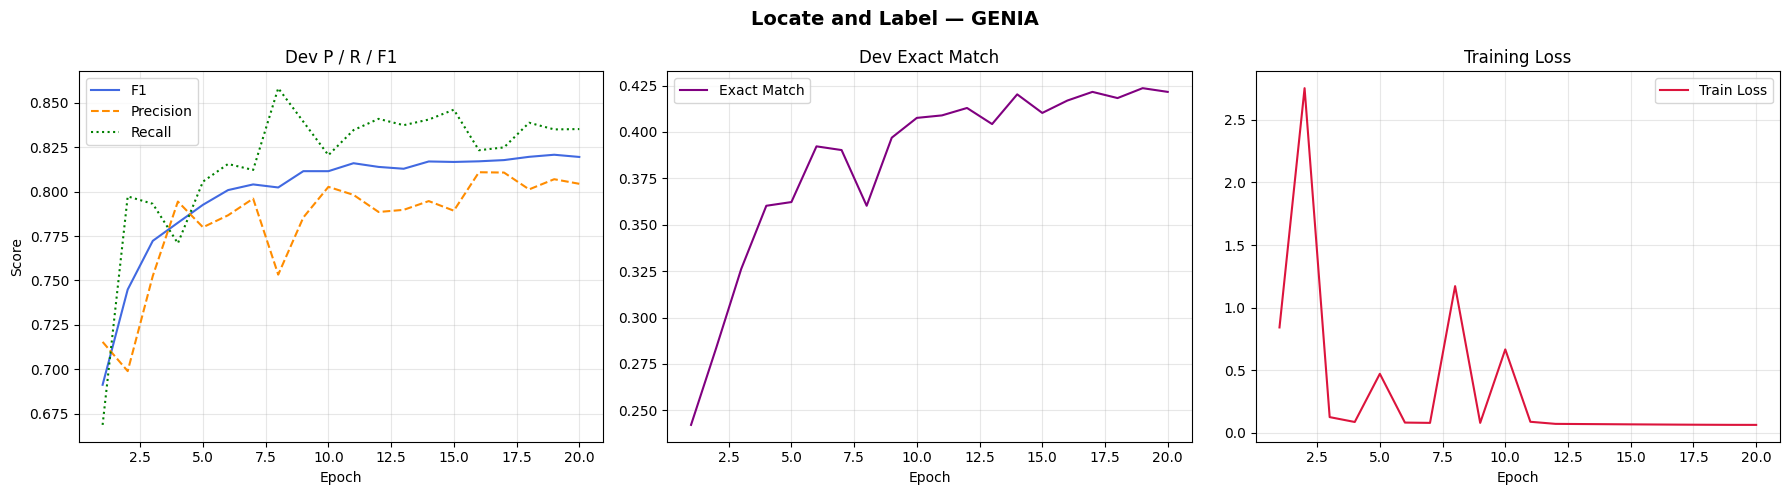

Curves saved to locate_and_label_curves.png


In [19]:
try:
    import matplotlib.pyplot as plt

    epochs_done = [h["epoch"]      for h in history]
    f1_vals     = [h["f1"]         for h in history]
    prec_vals   = [h["precision"]  for h in history]
    rec_vals    = [h["recall"]     for h in history]
    em_vals     = [h["exact_match"]for h in history]
    loss_vals   = [h["train_loss"] for h in history]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    axes[0].plot(epochs_done, f1_vals,   label="F1",        color="royalblue")
    axes[0].plot(epochs_done, prec_vals, label="Precision", color="darkorange", linestyle="--")
    axes[0].plot(epochs_done, rec_vals,  label="Recall",    color="green",      linestyle=":")
    axes[0].set_title("Dev P / R / F1"); axes[0].legend(); axes[0].grid(True, alpha=0.3)
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Score")

    axes[1].plot(epochs_done, em_vals, label="Exact Match", color="purple")
    axes[1].set_title("Dev Exact Match"); axes[1].legend(); axes[1].grid(True, alpha=0.3)
    axes[1].set_xlabel("Epoch")

    axes[2].plot(epochs_done, loss_vals, label="Train Loss", color="crimson")
    axes[2].set_title("Training Loss"); axes[2].legend(); axes[2].grid(True, alpha=0.3)
    axes[2].set_xlabel("Epoch")

    plt.suptitle("Locate and Label — GENIA", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig("locate_and_label_curves.png", dpi=150)
    plt.show()
    print("Curves saved to locate_and_label_curves.png")
except ImportError:
    print("matplotlib not installed — skipping curves.")

## 16. Qualitative Inspection

In [20]:
model.eval()
N_SHOW = 10

print(f"{'─'*70}")
print("Sample predictions (first 10 dev sentences)")
print(f"{'─'*70}")

for idx in range(min(N_SHOW, len(dev_data))):
    sample = dev_data[idx]
    tokens = sample["tokens"]
    n      = len(tokens)

    wids = torch.tensor([tokens_to_ids(tokens, vocab)],     dtype=torch.long, device=device)
    cids = torch.tensor([encode_chars(tokens, char2id)],    dtype=torch.long, device=device)
    lens = torch.tensor([n],                                dtype=torch.long, device=device)

    with torch.no_grad():
        preds = model.predict(wids, cids, lens)[0]

    gold = load_gt_entities(sample["entities"], n)

    print(f"\n[{idx}] Tokens: {' '.join(tokens)}")

    print("  GOLD:", end="")
    for s, e, c in gold:
        print(f"  [{s}:{e}] '{' '.join(tokens[s:e+1])}' → {id2cat[c]}", end="")
    print()

    print("  PRED:", end="")
    for p in preds:
        print(f"  [{p.start}:{p.end}] '{' '.join(tokens[p.start:p.end+1])}' "
              f"→ {id2cat.get(p.label, '?')} ({p.score:.2f})", end="")
    print()
    print()

print(f"{'─'*70}")

──────────────────────────────────────────────────────────────────────
Sample predictions (first 10 dev sentences)
──────────────────────────────────────────────────────────────────────

[0] Tokens: Our results support the model proposing that the N-terminal domain confers calcium -signaling dependence on NFATx1 transactivation activity by regulating its intracellular localization through a protein module that associates with calcineurin and is a target of its phosphatase activity .
  GOLD:  [30:30] 'calcineurin' → protein  [8:9] 'N-terminal domain' → protein  [15:15] 'NFATx1' → protein  [37:37] 'phosphatase' → protein
  PRED:  [15:15] 'NFATx1' → protein (1.00)  [30:30] 'calcineurin' → protein (1.00)  [8:9] 'N-terminal domain' → protein (1.00)  [37:37] 'phosphatase' → protein (0.89)


[1] Tokens: These data suggest that, in this inflammatory model , initial activation of NF-kappaB occurs in alveolar macrophages and the ensuing production of TNF-alpha may propagate NF-kappaB activation 